# Ray Serve: replicas and per-replica resources

A three-deployment pipeline where the classifier runs two replicas with half a CPU each and a cap on in-flight requests.

**When to use it.** Sizing each stage of a serving pipeline on its own: more replicas for the hot stage, fewer for the cheap ones.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

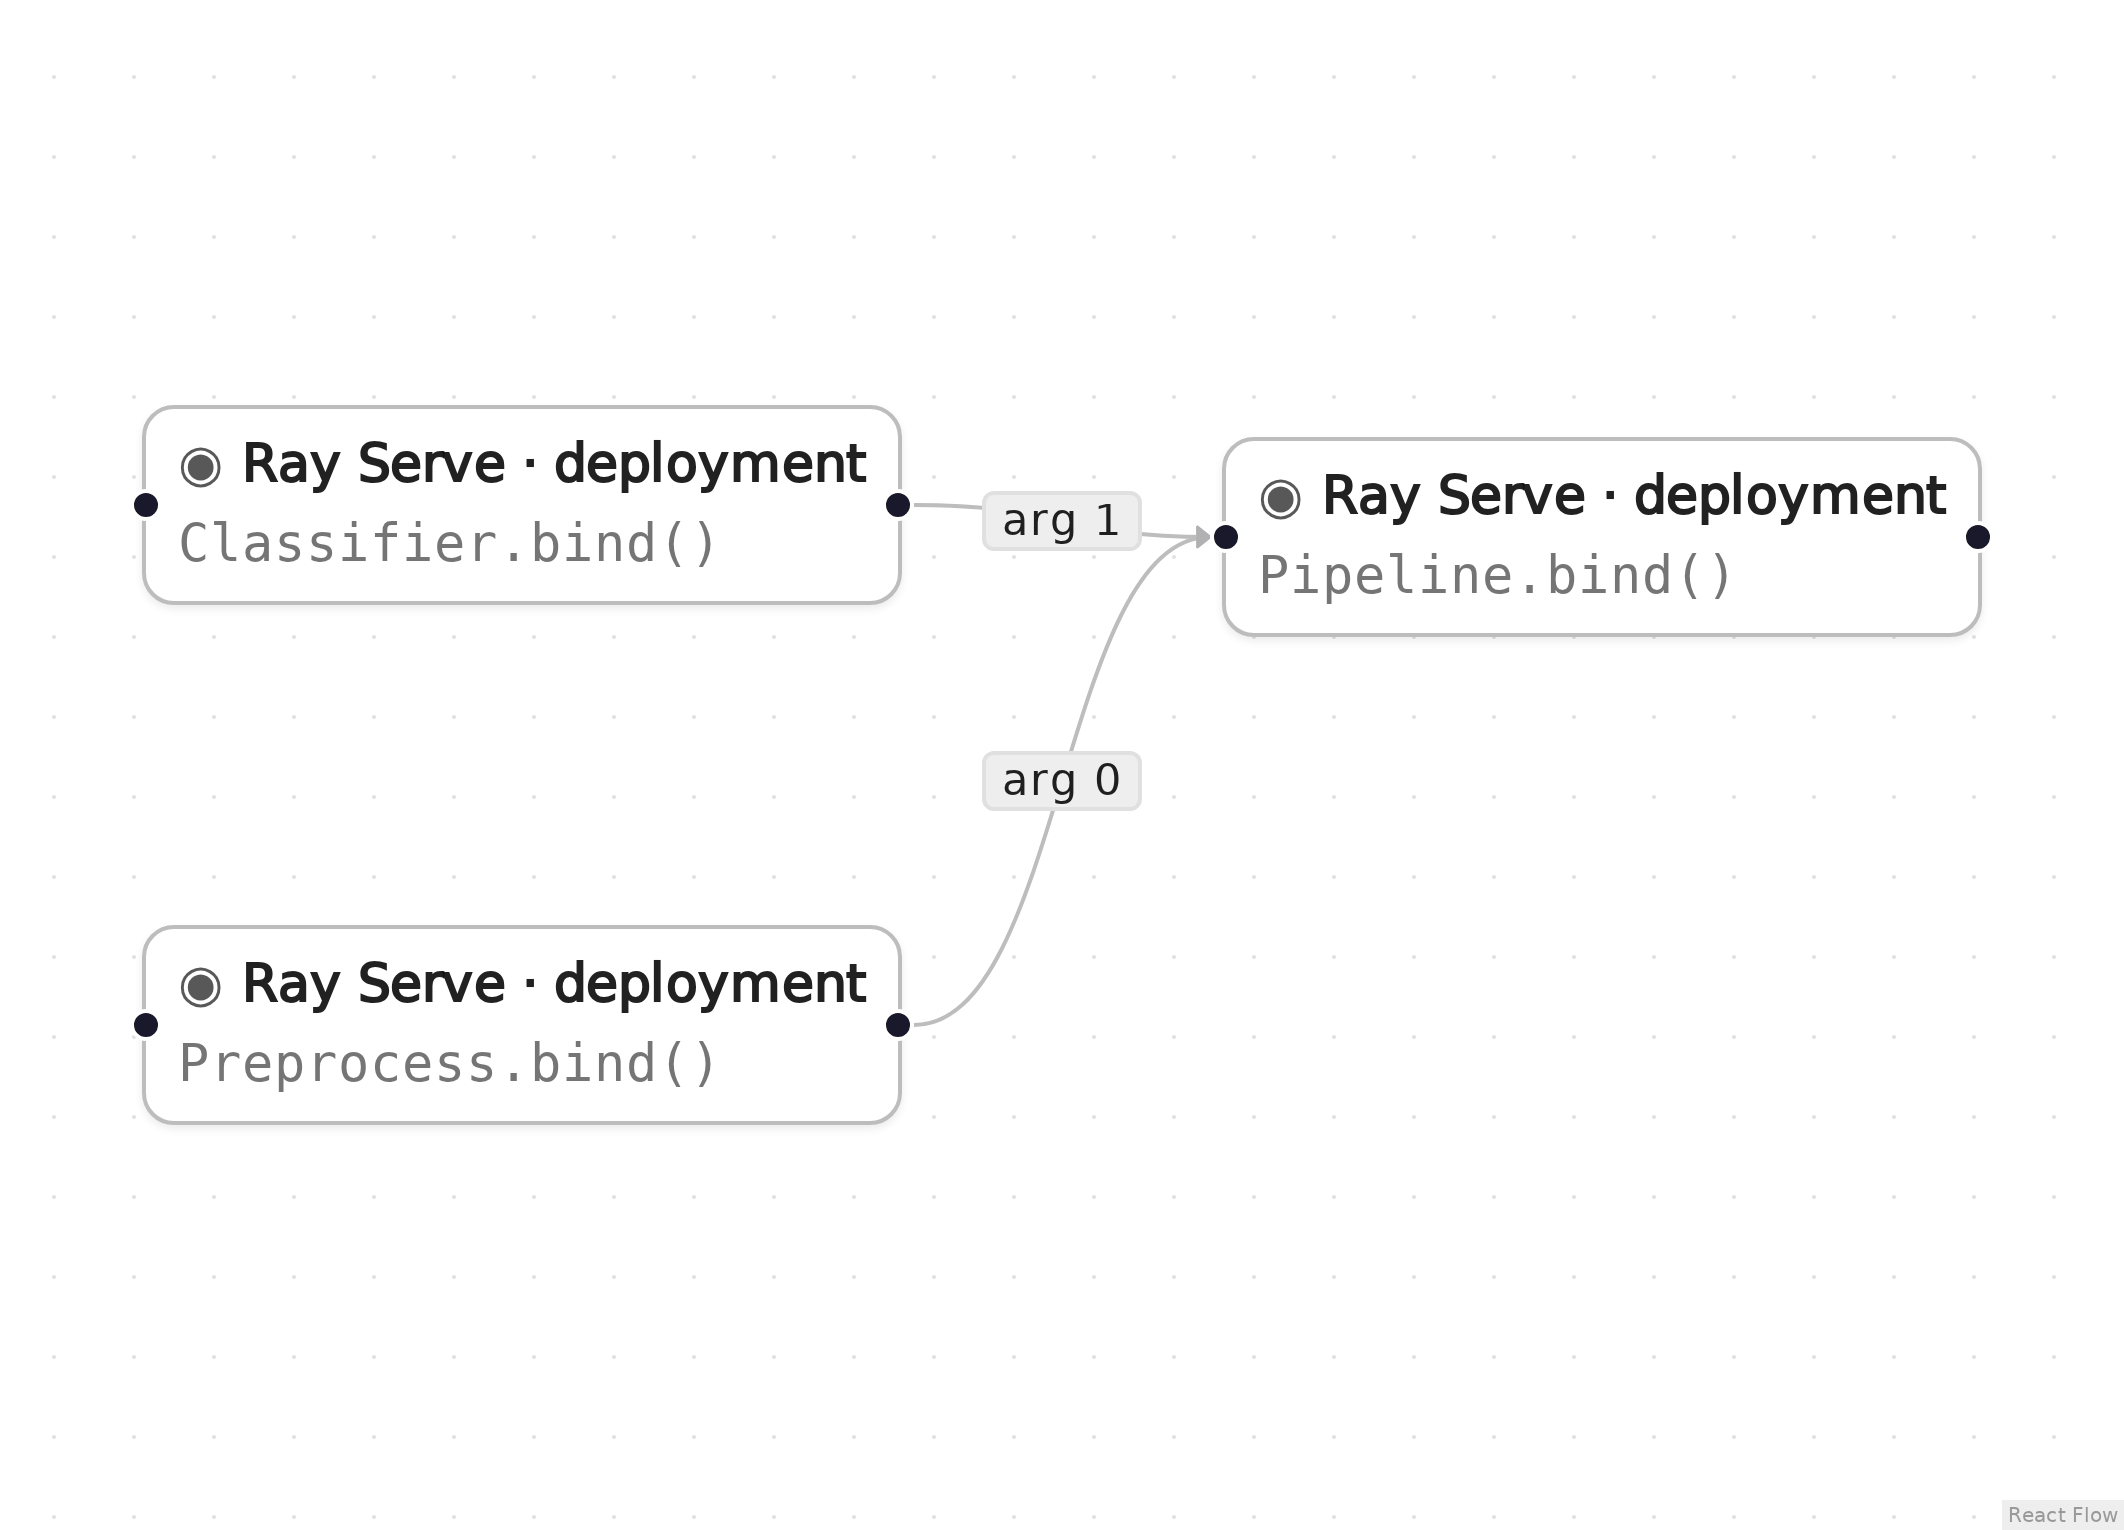

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
from ray import serve


@serve.deployment
class Preprocess:
    def __call__(self, text: str) -> str:
        return text.strip().lower()


@serve.deployment
class Classifier:
    def __call__(self, text: str) -> str:
        return "positive" if "good" in text else "negative"


@serve.deployment
class Pipeline:
    def __init__(self, preprocess, classifier):
        self.preprocess = preprocess
        self.classifier = classifier

    async def __call__(self, text: str) -> dict:
        clean = await self.preprocess.remote(text)
        label = await self.classifier.remote(clean)
        return {"text": clean, "label": label}

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

from ray import serve
import ray

if not ray.is_initialized():
    ray.init()

_deploy_n1 = Preprocess.bind()
_deploy_n2 = Classifier.options(num_replicas=2, ray_actor_options={"num_cpus": 0.5}, max_ongoing_requests=8).bind()
_deploy_n3 = Pipeline.bind(_deploy_n1, _deploy_n2)
serve.run(_deploy_n3)

DeploymentHandle(deployment='Pipeline')

## Check the result

The cell below checks that the generated code did what the graph describes. A Jupyter kernel already runs an asyncio event loop, so this cell awaits the Serve responses; in a plain Python script you would call `.result()` on them instead.

In [4]:
handle = serve.get_app_handle("default")
out = await handle.remote("  A GOOD day ")
assert out == {"text": "a good day", "label": "positive"}, out
replicas = serve.status().applications["default"].deployments["Classifier"].replica_states
assert replicas.get("RUNNING") == 2, replicas
print(out, "classifier replicas:", replicas)

{'text': 'a good day', 'label': 'positive'} classifier replicas: {'RUNNING': 2}


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
from ray import serve
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Deployment** (node `n1`, line 9)

```python
_deploy_n1 = Preprocess.bind()
```

A cheap preprocessing deployment with default settings (one replica).

**Deployment** (node `n2`, line 10)

```python
_deploy_n2 = Classifier.options(num_replicas=2, ray_actor_options={"num_cpus": 0.5}, max_ongoing_requests=8).bind()
```

.options(num_replicas=2, ray_actor_options={"num_cpus": 0.5}, max_ongoing_requests=8) sizes the classifier on its own.

**Deployment** (node `n3`, lines 11–12)

```python
_deploy_n3 = Pipeline.bind(_deploy_n1, _deploy_n2)
serve.run(_deploy_n3)
```

The ingress deployment receives handles to both and chains them per request.

## Clean up

Shut down Serve and then Ray, so the next notebook starts fresh.

In [5]:
from ray import serve

serve.shutdown()
ray.shutdown()